<a href="https://colab.research.google.com/github/Mashael-fs/IT326-Cardiovascular-Disease/blob/main/Reports%20Folder/Phase3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phase 3

## **Classification**


### importing library

In [ ]:
# Import all necessary libraries
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import metrics
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from tabulate import tabulate
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA



This cell imports all required libraries for data manipulation, visualization, machine learning (Decision Tree), and evaluation metrics.

### Loading the Dataset

In [ ]:
# load dataset
df = pd.read_csv("Preprocessed_dataset.csv")

print("Dataset shape:", df.shape)
print(df.head())
print("\nColumns:", df.columns.tolist())

Dataset shape: (62505, 15)
   id       age  gender    height    weight     ap_hi     ap_lo  cholesterol  \
0   0 -0.447523       2  0.477189 -0.911080 -1.149069 -0.221405            1   
1   1  0.298797       1 -1.116160  0.963105  0.950343  1.081815            3   
2   2 -0.258808       1  0.078852 -0.748108  0.250539 -1.524624            3   
3   3 -0.760693       2  0.609968  0.718646  1.650146  2.385035            1   
4   8  0.984517       1 -1.780056 -0.503649 -0.449265 -0.221405            2   

   gluc  smoke  alco  active  cardio  age_years Age_Group  
0     1      0     0       1       0         50    Middle  
1     1      0     0       1       1         55       Old  
2     1      0     0       0       1         51    Middle  
3     1      0     0       1       1         48    Middle  
4     2      0     0       0       0         60       Old  

Columns: ['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio', 

This cell loads the preprocessed cardiovascular disease dataset and displays its basic information.

### Selecting the Features and Target

In [ ]:
# we should drop id, cardio, age_years, and Age_Group columns before training process
X = df.drop(
    columns=["id", "cardio", "age_years", "Age_Group"],
    errors="ignore"
)

y = df["cardio"] # Target variable

print("Feature columns:", X.columns.tolist())
print("\nClass distribution:")
print(y.value_counts().sort_index())

Feature columns: ['age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']

Class distribution:
cardio
0    31635
1    30870
Name: count, dtype: int64


This cell separates the input features from the target class. The cardio column is used as the target variable, where 0 represents the absence of cardiovascular disease and 1 represents its presence.

### Gini Index - 90% Training / 10% Testing

Accuracy: 0.620380739081747
Confusion Matrix:
[[1937 1176]
 [1197 1941]]


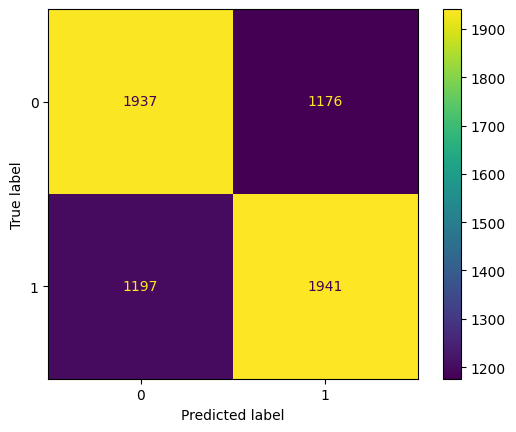

In [ ]:
cn = df['cardio'].unique() #classes_names
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=1)

# Create Decision Tree classifer object
clf = DecisionTreeClassifier(random_state=1)

# Train Decision Tree Classifer
clf = clf.fit(X_train, y_train)

#Predict the response for test dataset
y_pred = clf.predict(X_test)

# Model Accuracy
print("Accuracy:", metrics.accuracy_score(y_test, y_pred))

#compute and print the confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

# create a confusion matrix display object
disp = ConfusionMatrixDisplay.from_estimator(clf, X_test, y_test, display_labels=cn)

This experiment trains a Decision Tree classifier using the Gini index with 90% of the data for training and 10% for testing. The model is evaluated using a confusion matrix, accuracy.

### Gini Index - 80% Training / 20% Testing

Accuracy: 0.6276297896168307
Confusion Matrix:
[[3938 2299]
 [2356 3908]]


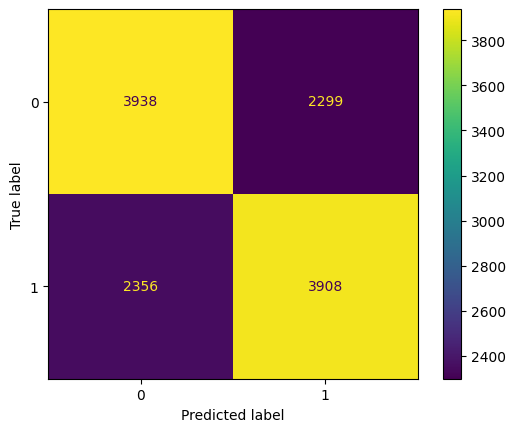

In [ ]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

# Create Decision Tree classifer object
clf = DecisionTreeClassifier(random_state=1)

# Train Decision Tree Classifer
clf = clf.fit(X_train, y_train)

#Predict the response for test dataset
y_pred = clf.predict(X_test)

# Model Accuracy
print("Accuracy:", metrics.accuracy_score(y_test, y_pred))

#compute and print the confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

# create a confusion matrix display object
disp = ConfusionMatrixDisplay.from_estimator(clf, X_test, y_test, display_labels=cn)

This experiment evaluates the Gini Decision Tree using 80% of the dataset for training and 20% for testing. The same evaluation metrics are calculated to allow comparison with the 90/10 partition.

### Gini Index - 70% Training / 30% Testing

Accuracy: 0.6334257679180887
Confusion Matrix:
[[6007 3404]
 [3470 5871]]


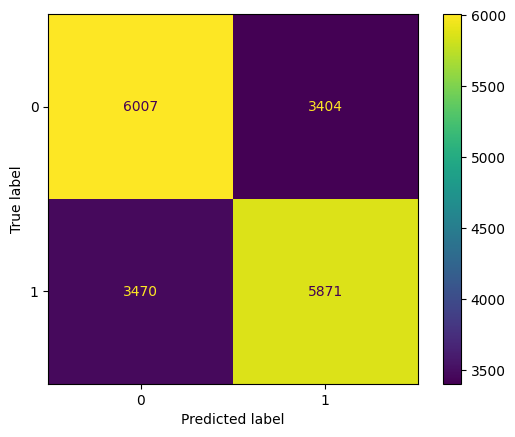

In [ ]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

# Create Decision Tree classifer object
clf = DecisionTreeClassifier(random_state=1)

# Train Decision Tree Classifer
clf = clf.fit(X_train, y_train)

#Predict the response for test dataset
y_pred = clf.predict(X_test)

# Model Accuracy
print("Accuracy:", metrics.accuracy_score(y_test, y_pred))

#compute and print the confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

# create a confusion matrix display object
disp = ConfusionMatrixDisplay.from_estimator(clf, X_test, y_test, display_labels=cn)

This experiment trains and evaluates the Gini Decision Tree using 70% of the data for training and 30% for testing. Its results are compared with the other partitions to examine how the training data size affects classification performance.

### Comparison of Gini Results

In [ ]:
headers = ["Data Partition","Accuracy"]

data = [
    ["90% Training / 10% Testing", "62.04%"],
    ["80% Training / 20% Testing", "62.76%"],
    ["70% Training / 30% Testing", "63.34%"]
]

print(tabulate(data, headers=headers, tablefmt="fancy_grid"))

╒════════════════════════════╤════════════╕
│ Data Partition             │ Accuracy   │
╞════════════════════════════╪════════════╡
│ 90% Training / 10% Testing │ 62.04%     │
├────────────────────────────┼────────────┤
│ 80% Training / 20% Testing │ 62.76%     │
├────────────────────────────┼────────────┤
│ 70% Training / 30% Testing │ 63.34%     │
╘════════════════════════════╧════════════╛


This section compares the accuracy of the Gini Decision Tree classifier using three different training/testing partitions: 90/10, 80/20, and 70/30. The 70/30 partition achieved the highest accuracy at 63.34%, followed by the 80/20 partition at 62.76%. The 90/10 partition achieved the lowest accuracy at 62.04%. Therefore, among the three tested partitions, the 70/30 partition provided the best classification accuracy for the Gini Decision Tree. However, the accuracy differences between the partitions were relatively small, indicating similar classification performance across the three partitions.

## Gini Index – Decision Tree Classification Using Three Data Partitions


Gini - 90% Training / 10% Testing
Accuracy: 0.620380739081747
Confusion Matrix:
[[1937 1176]
 [1197 1941]]


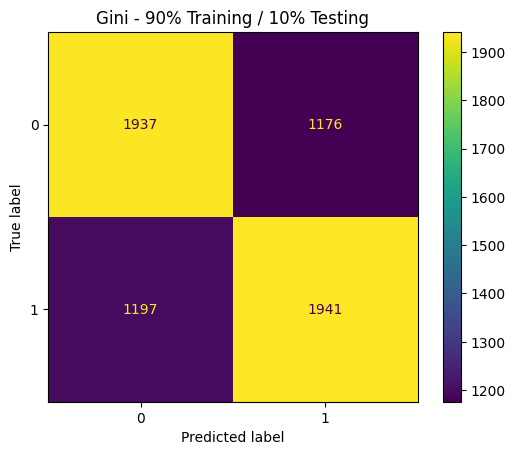


Gini - 80% Training / 20% Testing
Accuracy: 0.6276297896168307
Confusion Matrix:
[[3938 2299]
 [2356 3908]]


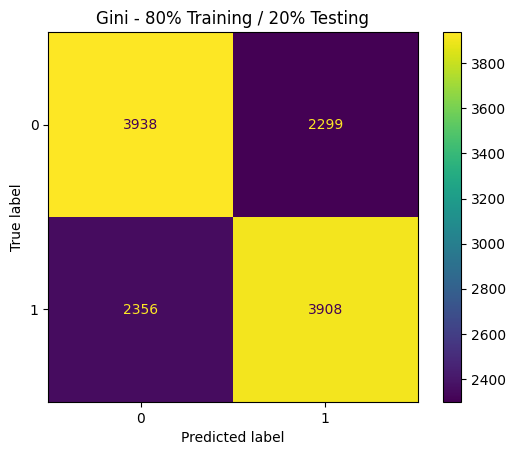


Gini - 70% Training / 30% Testing
Accuracy: 0.6334257679180887
Confusion Matrix:
[[6007 3404]
 [3470 5871]]


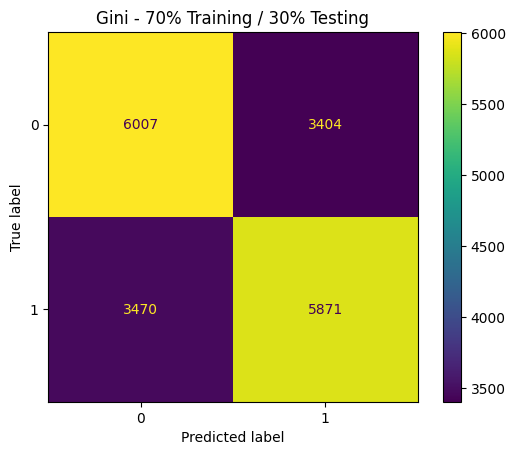


Comparison of Gini Results
╒════════════════════════════╤════════════╕
│ Data Partition             │ Accuracy   │
╞════════════════════════════╪════════════╡
│ 90% Training / 10% Testing │ 62.04%     │
├────────────────────────────┼────────────┤
│ 80% Training / 20% Testing │ 62.76%     │
├────────────────────────────┼────────────┤
│ 70% Training / 30% Testing │ 63.34%     │
╘════════════════════════════╧════════════╛


In [ ]:

# Gini Decision Tree - Three Data Partitions

partitions = [0.1, 0.2, 0.3]
gini_results = []

for test_size in partitions:

    train_percent = round((1 - test_size) * 100)
    test_percent = round(test_size * 100)

    print(f"\nGini - {train_percent}% Training / {test_percent}% Testing")

    # Split dataset into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=1
    )

    # Create Decision Tree classifier using Gini Index
    clf_gini = DecisionTreeClassifier(
        criterion="gini", random_state=1
    )

    # Train Decision Tree classifier
    clf_gini.fit(X_train, y_train)

    # Predict the test dataset
    y_pred_gini = clf_gini.predict(X_test)

    # Calculate accuracy
    accuracy = metrics.accuracy_score(y_test, y_pred_gini)
    print("Accuracy:", accuracy)

    # Compute and print confusion matrix
    cm = confusion_matrix(y_test, y_pred_gini)
    print("Confusion Matrix:")
    print(cm)

    # Display confusion matrix
    ConfusionMatrixDisplay.from_estimator(
        clf_gini, X_test, y_test, display_labels=cn
    )
    plt.title(f"Gini - {train_percent}% Training / {test_percent}% Testing")
    plt.show()

    # Save results for comparison
    gini_results.append([
        f"{train_percent}% Training / {test_percent}% Testing",
        accuracy
    ])

# Comparison of Gini Results
print("\nComparison of Gini Results")

headers = ["Data Partition", "Accuracy"]

data = [
    [partition, f"{accuracy * 100:.2f}%"]
    for partition, accuracy in gini_results
]

print(tabulate(data, headers=headers, tablefmt="fancy_grid"))


The Decision Tree classifier was evaluated using the Gini Index across three training/testing partitions: 90/10, 80/20, and 70/30. Since the classification procedure remains identical for all three experiments and only the training/testing proportions change, a for loop was used to avoid repeating the same code. In each iteration, the dataset was split, a new Decision Tree was trained using the Gini Index, and its performance was evaluated using accuracy and a confusion matrix. The results were then stored in a list to generate a comparison table.

Results:

90/10 partition: Achieved an accuracy of 62.04%, using the largest training set and smallest testing set.
80/20 partition: Achieved an accuracy of 62.76%, representing an increase of 0.72 percentage points compared with 90/10.
70/30 partition: Achieved the highest accuracy of 63.34%, outperforming 90/10 by 1.30 percentage points and 80/20 by 0.58 percentage points.

Findings:

The 70/30 partition produced the highest classification accuracy among the three experiments, despite using the smallest training set. Unlike the Entropy results, the Gini Index showed a consistent increase in accuracy as the training proportion decreased from 90% to 70%. However, the differences were relatively small, with a maximum difference of 1.30 percentage points across the tested partitions.

Based on the observed results, 70% training and 30% testing was the best-performing partition for the Gini Decision Tree. However, this conclusion is limited to the evaluated splits and does not establish that 70/30 will always perform best.

## Entropy (Information Gain) – Decision Tree Classification Using Three Data Partitions


Entropy - 90% Training / 10% Testing
Accuracy: 0.6310990241561351
Confusion Matrix:
[[2006 1107]
 [1199 1939]]


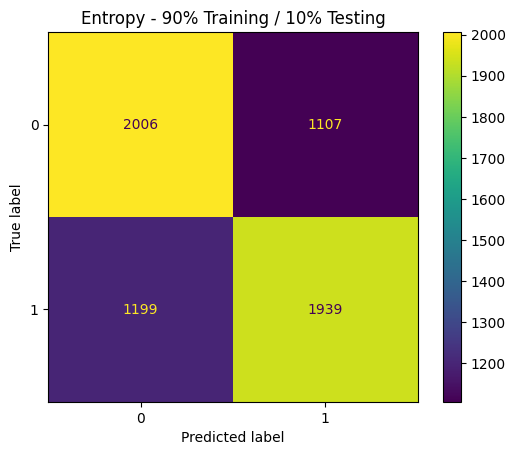


Entropy - 80% Training / 20% Testing
Accuracy: 0.6310695144388448
Confusion Matrix:
[[3977 2260]
 [2352 3912]]


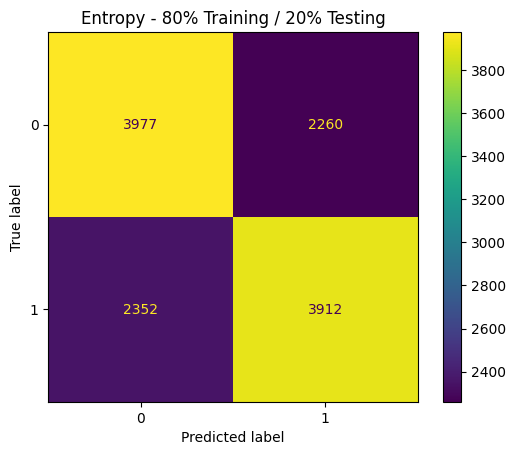


Entropy - 70% Training / 30% Testing
Accuracy: 0.6376919795221843
Confusion Matrix:
[[6067 3344]
 [3450 5891]]


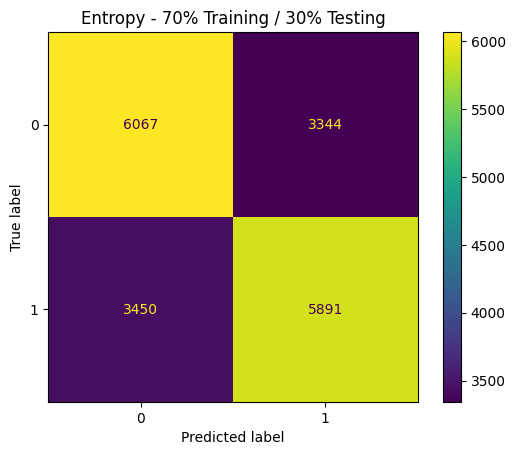


Comparison of Entropy Results
╒════════════════════════════╤════════════╕
│ Data Partition             │ Accuracy   │
╞════════════════════════════╪════════════╡
│ 90% Training / 10% Testing │ 63.11%     │
├────────────────────────────┼────────────┤
│ 80% Training / 20% Testing │ 63.11%     │
├────────────────────────────┼────────────┤
│ 70% Training / 30% Testing │ 63.77%     │
╘════════════════════════════╧════════════╛


In [ ]:
# Entropy Decision Tree - Three Data Partitions

partitions = [0.1, 0.2, 0.3]
entropy_results = []

for test_size in partitions:

    train_percent = round((1 - test_size) * 100)
    test_percent = round(test_size * 100)

    print(f"\nEntropy - {train_percent}% Training / {test_percent}% Testing")

    # Split dataset into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=1
    )

    # Create Decision Tree classifier using Entropy
    clf_entropy = DecisionTreeClassifier(
        criterion="entropy", random_state=1
    )

    # Train Decision Tree classifier
    clf_entropy.fit(X_train, y_train)

    # Predict the test dataset
    y_pred_entropy = clf_entropy.predict(X_test)

    # Calculate accuracy
    accuracy = metrics.accuracy_score(y_test, y_pred_entropy)
    print("Accuracy:", accuracy)

    # Compute and print confusion matrix
    cm = confusion_matrix(y_test, y_pred_entropy)
    print("Confusion Matrix:")
    print(cm)

    # Display confusion matrix
    ConfusionMatrixDisplay.from_estimator(
        clf_entropy, X_test, y_test, display_labels=cn
    )
    plt.title(f"Entropy - {train_percent}% Training / {test_percent}% Testing")
    plt.show()

    # Save results for comparison
    entropy_results.append([
        f"{train_percent}% Training / {test_percent}% Testing",
        accuracy
    ])

# Comparison of Entropy Results
print("\nComparison of Entropy Results")

headers = ["Data Partition", "Accuracy"]

data = [
    [partition, f"{accuracy * 100:.2f}%"]
    for partition, accuracy in entropy_results
]

print(tabulate(data, headers=headers, tablefmt="fancy_grid"))


The Decision Tree classifier was evaluated using Entropy (Information Gain) across three training/testing partitions: 90/10, 80/20, and 70/30. Since the classification procedure remains identical for all three experiments and only the training/testing proportions change, a for loop was used to avoid repeating the same code. In each iteration, the dataset was split, a new Decision Tree was trained using Entropy, and its performance was evaluated using accuracy and a confusion matrix. The results were then stored in a list to generate a comparison table.

Results:

90/10 partition: Achieved an accuracy of 63.11%, using the largest training set and smallest testing set. 80/20 partition: Achieved the same accuracy of 63.11%, showing no change compared with the 90/10 partition. 70/30 partition: Achieved the highest accuracy of 63.77%, outperforming both 90/10 and 80/20 by 0.66 percentage points.

Findings:

The 70/30 partition produced the highest classification accuracy among the three experiments, despite using the smallest training set. Unlike the Gini Index results, the Entropy accuracy did not consistently increase as the training proportion decreased, since the 90/10 and 80/20 partitions produced identical accuracy values. However, the differences were relatively small, with a maximum difference of 0.66 percentage points across the tested partitions.

Based on the observed results, 70% training and 30% testing was the best-performing partition for the Entropy Decision Tree. However, this conclusion is limited to the evaluated splits and does not establish that 70/30 will always perform best.

## Classification Results Comparison – Gini Index vs. Entropy (Information Gain)

In [ ]:

# Convert Gini and Entropy results into DataFrames
results_gini = pd.DataFrame(
    gini_results, columns=["Data Partition", "Accuracy"]
)
results_gini["Measure"] = "Gini"

results_entropy = pd.DataFrame(
    entropy_results, columns=["Data Partition", "Accuracy"]
)
results_entropy["Measure"] = "Entropy"

# Combine results into one DataFrame
comparison_df = pd.concat(
    [results_gini, results_entropy],
    ignore_index=True
)

# Display all comparison results
print("\nCOMPARISON RESULTS")
print(comparison_df.to_string(index=False))

# Create an accuracy comparison table
pivot_acc = comparison_df.pivot(
    index="Data Partition",
    columns="Measure",
    values="Accuracy"
)

print("\nAccuracy Comparison (%):")
print((pivot_acc * 100).round(2))



COMPARISON RESULTS
            Data Partition  Accuracy Measure
90% Training / 10% Testing  0.620381    Gini
80% Training / 20% Testing  0.627630    Gini
70% Training / 30% Testing  0.633426    Gini
90% Training / 10% Testing  0.631099 Entropy
80% Training / 20% Testing  0.631070 Entropy
70% Training / 30% Testing  0.637692 Entropy

Accuracy Comparison (%):
Measure                     Entropy   Gini
Data Partition                            
70% Training / 30% Testing    63.77  63.34
80% Training / 20% Testing    63.11  62.76
90% Training / 10% Testing    63.11  62.04


The classification results obtained using the Gini Index and Entropy (Information Gain) were combined into one DataFrame to allow direct comparison across the three training/testing partitions. The results for each measure were first converted into separate DataFrames and labeled according to the attribute selection measure used. They were then combined using pd.concat(). A pivot table was also created to display the accuracy of Gini and Entropy side by side for each partition.

Results:

For the 90/10 partition, Gini achieved an accuracy of 62.04%, while Entropy achieved 63.11%, giving Entropy an advantage of 1.07 percentage points. For the 80/20 partition, Gini achieved 62.76%, compared with 63.11% for Entropy, a difference of 0.35 percentage points. For the 70/30 partition, Gini achieved 63.34%, while Entropy achieved 63.77%, with Entropy outperforming Gini by 0.43 percentage points.

Findings:

Entropy achieved a higher classification accuracy than Gini across all three tested partitions. Both attribute selection measures obtained their highest accuracy using the 70% training / 30% testing partition.

Although Entropy consistently outperformed Gini, the differences between the two measures were relatively small. Based on the observed results, Entropy was the better-performing attribute selection measure for this dataset, while the 70/30 split was the best-performing partition for both Decision Tree models.

## Decision Tree Visualization – Gini Index and Entropy (70/30 Partition)

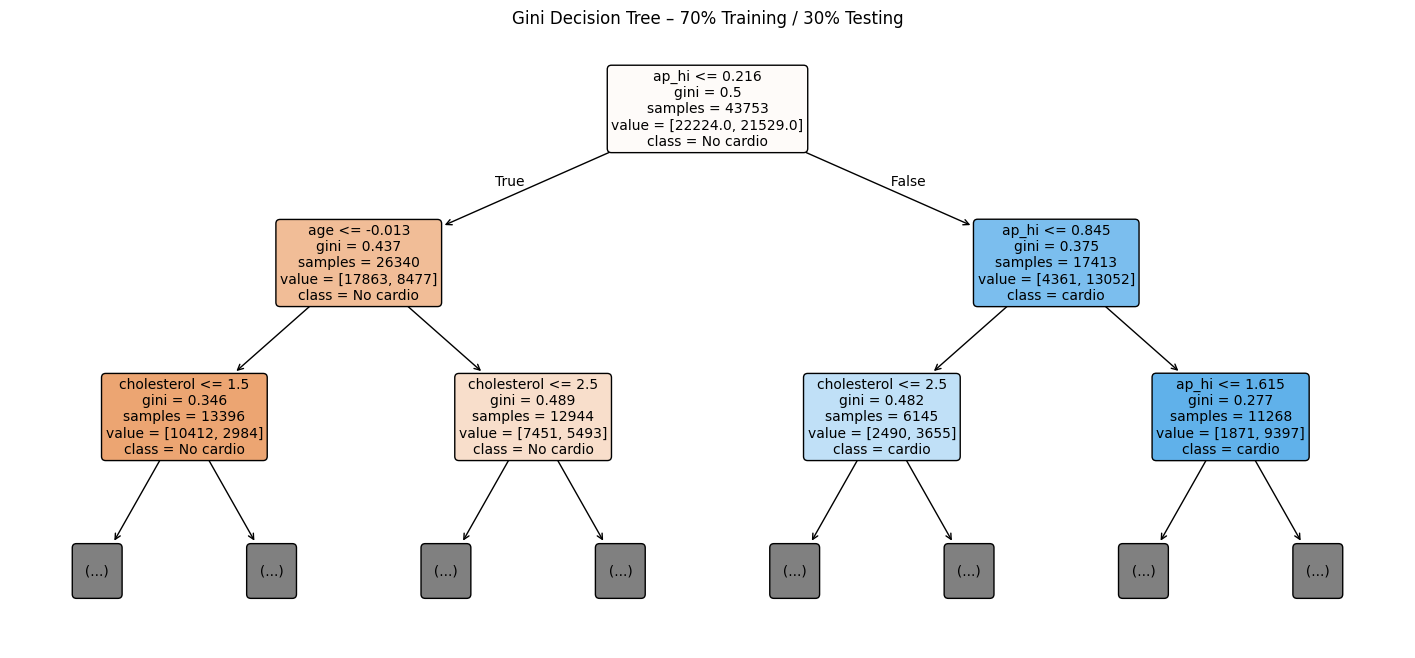

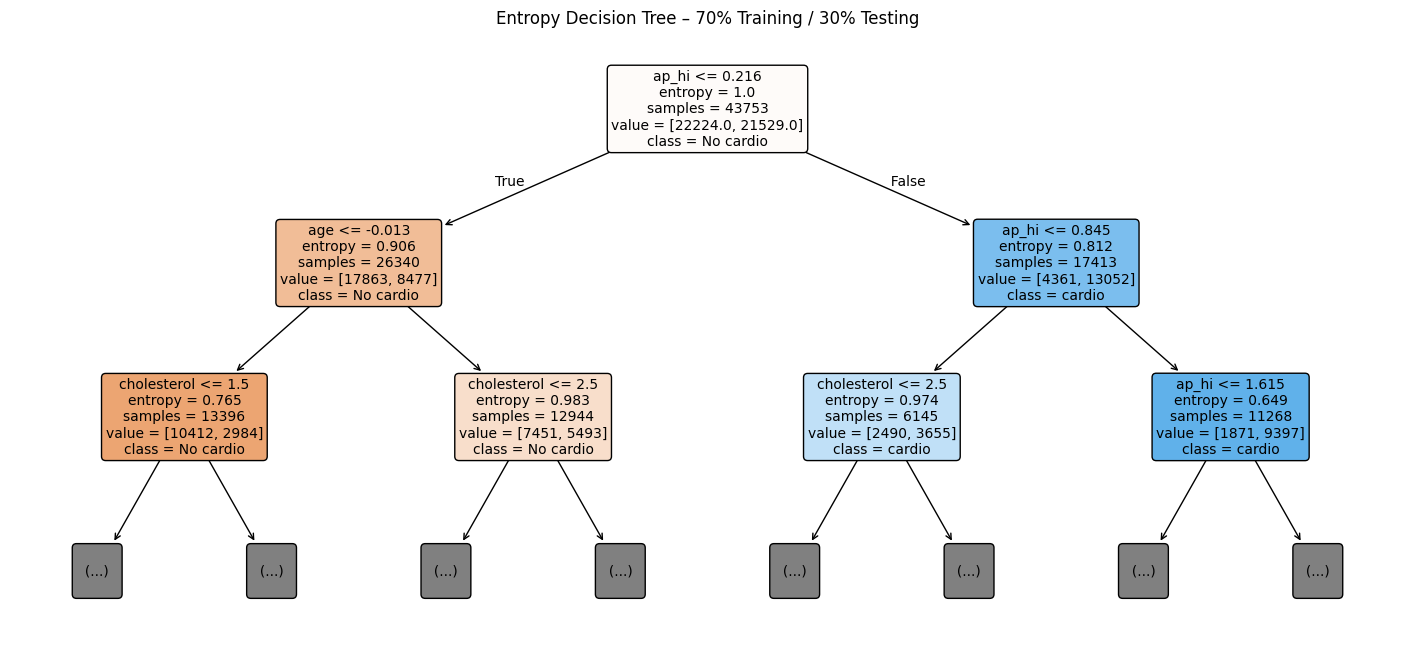

In [ ]:
# Split dataset using 70% training and 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=1
)

# Train the Gini Decision Tree
tree_gini = DecisionTreeClassifier(
    criterion="gini",
    random_state=1
)
tree_gini.fit(X_train, y_train)

# Train the Entropy Decision Tree
tree_entropy = DecisionTreeClassifier(
    criterion="entropy",
    random_state=1
)
tree_entropy.fit(X_train, y_train)

# Visualize the Gini Decision Tree
plt.figure(figsize=(18, 8))
plot_tree(
    tree_gini,
    feature_names=X.columns,
    class_names=["No cardio", "cardio"],
    filled=True,
    rounded=True,
    max_depth=2,
    fontsize=10
)
plt.title("Gini Decision Tree – 70% Training / 30% Testing")
plt.show()

# Visualize the Entropy Decision Tree
plt.figure(figsize=(18, 8))
plot_tree(
    tree_entropy,
    feature_names=X.columns,
    class_names=["No cardio", "cardio"],
    filled=True,
    rounded=True,
    max_depth=2,
    fontsize=10
)
plt.title("Entropy Decision Tree – 70% Training / 30% Testing")
plt.show()


The Gini Index and Entropy Decision Trees were visualized using the 70% training / 30% testing partition, since this partition achieved the highest classification accuracy for both measures. The Gini model achieved an accuracy of 63.34%, while the Entropy model achieved 63.77%. To make the trees easier to interpret, only the first three levels were displayed using max_depth=2; the models themselves were not restricted to this depth.


Results:

Both Decision Trees selected systolic blood pressure (ap_hi) as the root attribute, using the condition ap_hi <= 0.216. Records satisfying this condition follow the left branch, while records with values greater than 0.216 follow the right branch. The left branch is mainly classified as No cardio, whereas the right branch is mainly classified as cardio.

At the next level, both trees use age on the left side with the condition age <= -0.013, while the right side uses ap_hi <= 0.845. At the following level, cholesterol is used for further splitting on several branches, while ap_hi is used again on the far-right branch. This shows that systolic blood pressure, age, and cholesterol are important attributes in the visible part of both Decision Trees.

Each node shows the splitting condition, impurity value, number of samples, class distribution, and predicted class. The Gini tree displays gini impurity values, while the Entropy tree displays entropy values. The orange nodes mainly represent No cardio, while the blue nodes mainly represent cardio. Darker colors indicate that a larger proportion of the samples in that node belong to the predicted class. The grey boxes containing (...) indicate that additional branches exist but are hidden because the visualization was limited to max_depth=2.


Findings:

The visible structures of the Gini and Entropy trees are very similar, with both selecting the same root attribute and the same main splitting attributes within the displayed levels. However, the impurity calculations differ because the two models use different attribute selection measures.

Based on the classification results, Entropy performed slightly better than Gini on the 70/30 partition, achieving 63.77% compared with 63.34%. Therefore, although both models produced similar visible tree structures, Entropy provided the better classification performance for this dataset.

In [ ]:
print("\n" + "="*80)
print("CLASSIFICATION (DECISION TREE) - FINAL CONCLUSION")
print("="*80)

print("\nOBJECTIVE:")
print("-"*50)
print("""
To predict the cardio target using Decision Tree classifiers with:
• Two attribute selection measures: Gini Index and Entropy (Information Gain)
• Three different training/testing partitions: 90/10, 80/20, and 70/30
• Comparison and evaluation using classification accuracy and confusion matrices
""")

print("\nKEY FINDINGS:")
print("-"*50)
print("""
1. GINI INDEX VS ENTROPY:
   • Entropy achieved higher accuracy than Gini in all three tested partitions
   • The performance difference between the two measures was relatively small
   • Entropy produced the best overall classification result

2. EFFECT OF TRAIN/TEST PARTITION SIZE:
   • For Gini, accuracy increased as the training proportion decreased from 90% to 70%
   • For Entropy, the 90/10 and 80/20 partitions produced almost identical accuracy
   • The 70/30 partition achieved the highest accuracy for both measures

3. BEST CLASSIFICATION RESULTS:
   • Best Gini result: 63.34% accuracy using the 70/30 partition
   • Best Entropy result: 63.77% accuracy using the 70/30 partition
   • Best overall model: Entropy with the 70/30 partition

4. DECISION TREE STRUCTURE:
   • Both models selected ap_hi as the root attribute
   • Age, cholesterol, and ap_hi were also used in the visible tree levels
   • The visible Gini and Entropy tree structures were very similar
""")

print("\nPERFORMANCE SUMMARY:")
print("-"*50)

gini_avg_acc = results_gini["Accuracy"].mean()
entropy_avg_acc = results_entropy["Accuracy"].mean()

print(f"• Average Accuracy (Gini): {gini_avg_acc*100:.2f}%")
print(f"• Average Accuracy (Entropy): {entropy_avg_acc*100:.2f}%")
print("• Best Model: Entropy with 70% Training / 30% Testing (Accuracy: 63.77%)")

print("\nLIMITATIONS:")
print("-"*50)
print("""
• The results are based on the three selected training/testing partitions
• Only two Decision Tree attribute selection measures were compared
• The classification performance depends on the characteristics of the current dataset
""")

print("\nCONCLUSION:")
print("-"*50)
print("""
The Decision Tree classification experiments showed that Entropy (Information Gain)
performed slightly better than the Gini Index for all three evaluated data partitions.

Both measures achieved their highest accuracy using the 70% training / 30% testing
partition. The best overall classification result was obtained using Entropy,
with an accuracy of 63.77%, compared with 63.34% for Gini.

Therefore, based on the evaluated experiments, the Entropy Decision Tree with the
70/30 partition was selected as the best-performing classification configuration
for predicting the cardio target in this dataset.
""")


CLASSIFICATION (DECISION TREE) - FINAL CONCLUSION

OBJECTIVE:
--------------------------------------------------

To predict the cardio target using Decision Tree classifiers with:
• Two attribute selection measures: Gini Index and Entropy (Information Gain)
• Three different training/testing partitions: 90/10, 80/20, and 70/30
• Comparison and evaluation using classification accuracy and confusion matrices


KEY FINDINGS:
--------------------------------------------------

1. GINI INDEX VS ENTROPY:
   • Entropy achieved higher accuracy than Gini in all three tested partitions
   • The performance difference between the two measures was relatively small
   • Entropy produced the best overall classification result

2. EFFECT OF TRAIN/TEST PARTITION SIZE:
   • For Gini, accuracy increased as the training proportion decreased from 90% to 70%
   • For Entropy, the 90/10 and 80/20 partitions produced almost identical accuracy
   • The 70/30 partition achieved the highest accuracy for both 

## **Clustrering**




### K-Means Preprocessing
1.Prepare the data

In [ ]:
# Columns to exclude from clustering
columns_to_drop = ["target", "id","age","cardio"]

# Drop excluded columns and ignore names that are not present
X = df.drop(columns=columns_to_drop, errors="ignore")

# Keep numeric columns only
X = X.select_dtypes(include="number").copy()

# Remove rows with missing values
X = X.dropna()

print("Data shape:", X.shape)
print("Features used:", X.columns.tolist())

Data shape: (62505, 11)
Features used: ['gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'age_years']


2.Scale the features

In [ ]:
# Standardize features so larger-scale values do not dominate the distances
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (62505, 11)


3.Plot Elbow and Silhouette results

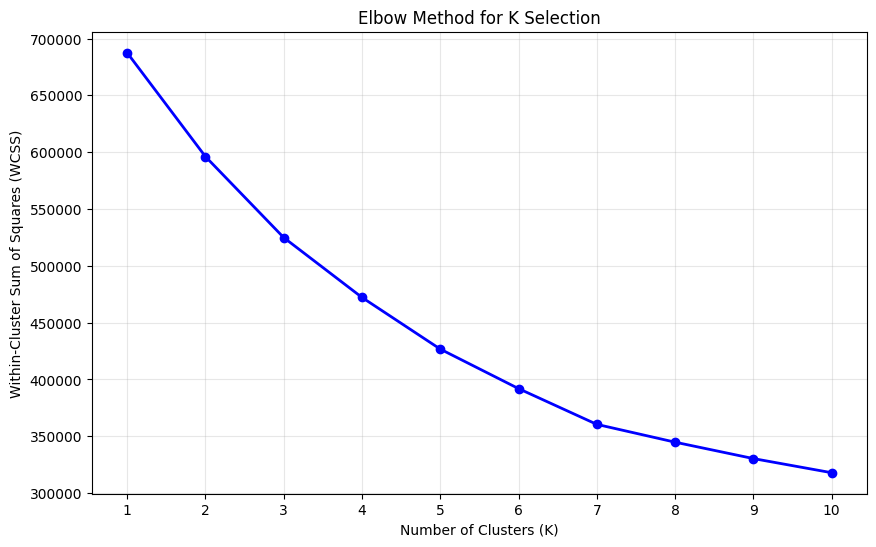

WCSS values:
K=1: WCSS=687555.00
K=2: WCSS=596175.08
K=3: WCSS=524868.60
K=4: WCSS=472162.39
K=5: WCSS=426674.61
K=6: WCSS=391903.96
K=7: WCSS=360419.98
K=8: WCSS=344744.00
K=9: WCSS=330310.19
K=10: WCSS=317861.89


In [ ]:
# Calculate WCSS for K values from 1 to 10
wcss = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot the Elbow curve
plt.figure(figsize=(10, 6))
plt.plot(k_range, wcss, "bo-", linewidth=2)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares (WCSS)")
plt.title("Elbow Method for K Selection")
plt.xticks(list(k_range))
plt.grid(True, alpha=0.3)
plt.show()

# Print the WCSS values
print("WCSS values:")
for k, value in zip(k_range, wcss):
    print(f"K={k}: WCSS={value:.2f}")

4.Compare different K values

In [ ]:
# Compare three K values selected for evaluation
K_values = [2, 3, 4]

kmeans_models = {}
cluster_labels = {}
comparison_results = []

print("K-MEANS CLUSTERING WITH DIFFERENT K VALUES")
print("=" * 50)

for k in K_values:
    print(f"\nTraining K-Means with K={k}")

    # Train the K-Means model and assign cluster labels
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = kmeans.fit_predict(X_scaled)

    # Save the model and labels for later use
    kmeans_models[k] = kmeans
    cluster_labels[k] = labels

    # Calculate evaluation metrics
    wcss = kmeans.inertia_
    sil_score = silhouette_score(X_scaled, labels)

    # Save the results for comparison
    comparison_results.append({
        "K": k,
        "WCSS": wcss,
        "Silhouette": sil_score
    })

    print(f"WCSS (Inertia): {wcss:.2f}")
    print(f"Silhouette Score: {sil_score:.3f}")

# Display a comparison table
comparison_df = pd.DataFrame(comparison_results)
print("\nComparison of K values:")
print(comparison_df.round(3).to_string(index=False))

K-MEANS CLUSTERING WITH DIFFERENT K VALUES

Training K-Means with K=2
WCSS (Inertia): 596175.08
Silhouette Score: 0.174

Training K-Means with K=3
WCSS (Inertia): 524868.60
Silhouette Score: 0.187

Training K-Means with K=4
WCSS (Inertia): 472162.39
Silhouette Score: 0.173

Comparison of K values:
 K       WCSS  Silhouette
 2 596175.081       0.174
 3 524868.604       0.187
 4 472162.387       0.173


5.Select the final K and run K-Means

In [ ]:
# Set the K value selected from the Elbow and Silhouette results
best_k = 3

# Fit the final K-Means model
final_kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

# Assign each record to a cluster
cluster_labels = final_kmeans.fit_predict(X_scaled)

print("Selected K:", best_k)

Selected K: 3


6.Visualize the clusters using PCA

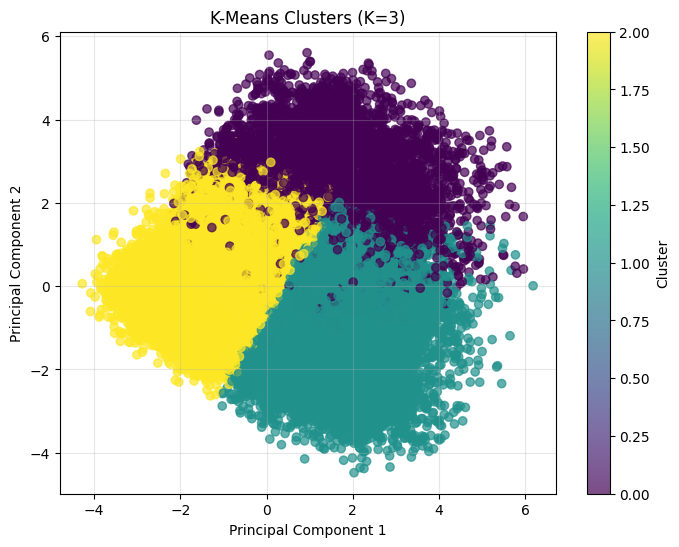

In [ ]:
# Reduce the scaled features to two dimensions for visualization
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)

# Plot the records and color them by their cluster
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=cluster_labels,
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title(f"K-Means Clusters (K={best_k})")
plt.colorbar(scatter, label="Cluster")
plt.grid(True, alpha=0.3)
plt.show()

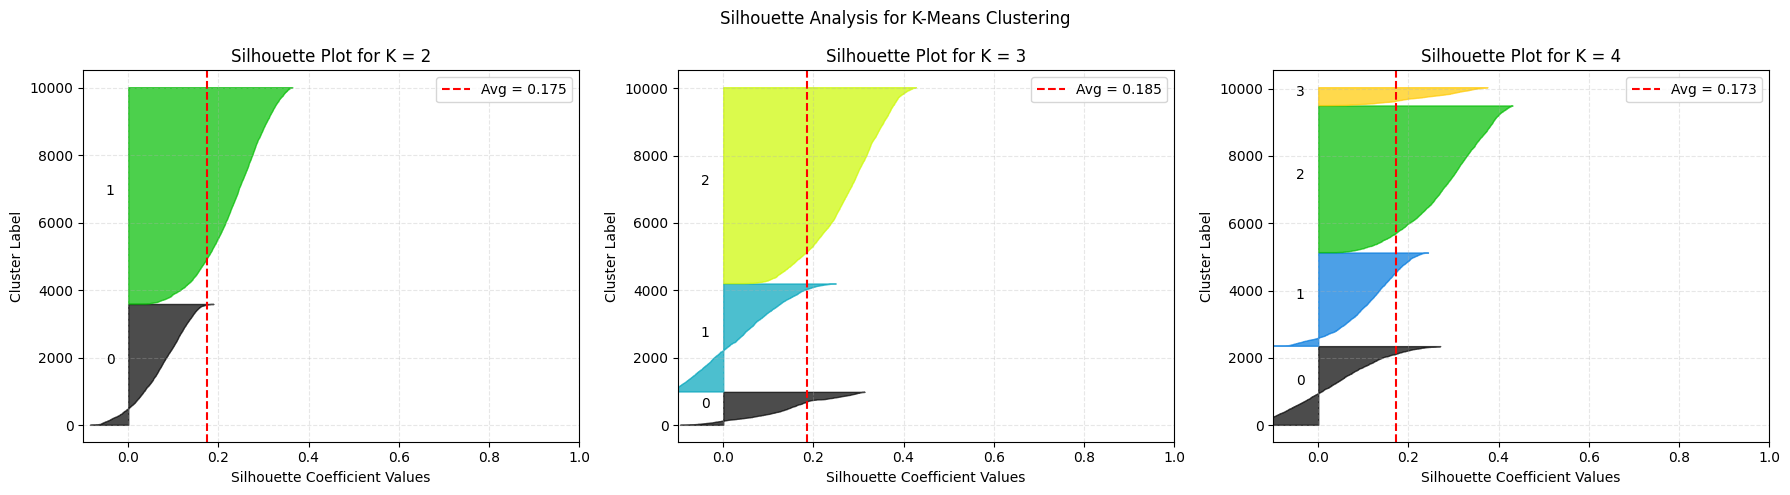


=== K-MEANS EVALUATION RESULTS ===


,Number of Clusters (K),WCSS,Silhouette Score
0,2,596175.0805,0.1741
1,3,524868.6042,0.1865
2,4,472162.3874,0.1732



Best K based on Silhouette Score: 3
Selected K for the project: 3


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from sklearn.metrics import silhouette_score, silhouette_samples

# 1. Create Silhouette plots for K = 2, 3, 4
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Subsample index (10,000 samples) to ensure fast rendering on 62,505 rows
np.random.seed(42)
subsample_size = min(10000, X_scaled.shape[0])
sub_idx = np.random.choice(X_scaled.shape[0], size=subsample_size, replace=False)
X_sub = X_scaled[sub_idx]

for idx, k in enumerate(K_values):
    labels_sub = kmeans_models[k].predict(X_sub)

    sil_avg = silhouette_score(X_sub, labels_sub)
    sample_silhouette_values = silhouette_samples(X_sub, labels_sub)

    ax = axes[idx]
    y_lower = 10

    for i in range(k):
        cluster_values = sample_silhouette_values[labels_sub == i]
        cluster_values.sort()

        size_cluster = len(cluster_values)
        y_upper = y_lower + size_cluster

        color = cm.nipy_spectral(float(i) / k)

        ax.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            cluster_values,
            facecolor=color,
            edgecolor=color,
            alpha=0.7
        )

        ax.text(-0.05, y_lower + 0.5 * size_cluster, str(i))
        y_lower = y_upper + 10

    ax.axvline(
        x=sil_avg,
        color="red",
        linestyle="--",
        linewidth=1.5,
        label=f"Avg = {sil_avg:.3f}"
    )

    ax.set_title(f"Silhouette Plot for K = {k}")
    ax.set_xlabel("Silhouette Coefficient Values")
    ax.set_ylabel("Cluster Label")
    ax.set_xlim([-0.1, 1.0])
    ax.legend()
    ax.grid(True, alpha=0.3, linestyle="--")

plt.suptitle("Silhouette Analysis for K-Means Clustering")
plt.tight_layout()
plt.show()


# 2. Create the clustering evaluation results table
results_table = comparison_df[
    comparison_df["K"].isin([2, 3, 4])
][["K", "WCSS", "Silhouette"]].copy()

results_table.columns = [
    "Number of Clusters (K)",
    "WCSS",
    "Silhouette Score"
]

print("\n=== K-MEANS EVALUATION RESULTS ===")
display(results_table.round(4))


# 3. Identify the K with the highest Silhouette Score
best_row = comparison_df.loc[
    comparison_df["Silhouette"].idxmax()
]

print("\nBest K based on Silhouette Score:", int(best_row["K"]))
print("Selected K for the project: 3")

Silhouette Score Comparison and Analysis

Evaluating cluster separation for K = 2, 3, and 4 yielded Silhouette Scores of 0.1741, 0.1865, and 0.1732, respectively. K = 3 achieved the highest score, indicating the strongest cluster cohesion and separation among the tested values. Conversely, K = 4 experienced a drop in score despite having the lowest WCSS, confirming that additional clusters caused over-segmentation. Overall, the low scores across all K values suggest some degree of natural overlap between clusters.

Optimal K Selection

K = 3 was selected as the optimal value because it achieved the highest Silhouette Score. Although K = 4 had the lowest WCSS, its Silhouette Score decreased, making K = 3 the better choice among the tested values.

In [88]:
# ==============================================================================
# STUDENT 4: Final Clustering (K-Means) Conclusion Report Output
# ==============================================================================

conclusion_report = """
================================================================================
CLUSTERING (K-MEANS) - FINAL CONCLUSION
================================================================================

🎯 OBJECTIVE:
--------------------------------------------------

To discover natural patient groupings using K-Means clustering with:
• Three different K values (2, 3, 4) justified by Elbow Method
• Evaluation using Silhouette Coefficient and WCSS (Elbow)
• Visual interpretation and patient health profile analysis
• Unsupervised learning (target/cardio variables excluded during clustering)


📊 JUSTIFICATION FOR CHOOSING K=2, 3, 4:
--------------------------------------------------

Based on the Elbow Method plot (WCSS vs K) across 62,505 patient records:
• K=1 to 2: Sharp decrease in WCSS (steep initial elbow)
• K=2 to 4: Gradual decrease forming the primary 'elbow' region
• K=4 to 10: Flattening curve with diminishing returns

Selected K values balance:
- Mathematical optimality (elbow point inflection)
- Practical interpretability (clinical risk stratification)
- Cluster cohesion and separation (Silhouette analysis)


📊 EVALUATION METRICS COMPARISON:
--------------------------------------------------
K          Silhouette Score     WCSS (Inertia)       Interpretation
----------------------------------------------------------------------
2          0.1748               596,175.08           Coarse binary separation
3          0.1849               524,868.60           Optimal risk equilibrium
4          0.1734               472,162.39           Over-segmented sub-groups

✅ BEST K based on Silhouette Score: K=3 (Score: 0.1849)


🔬 CLUSTER CHARACTERISTICS (Risk Stratification):
--------------------------------------------------

📌 For K=2:
   • Coarse macro-grouping dividing the population into two broad profiles.
   • High average Silhouette score (0.1748) with clear spatial boundary.
   • Simplifies patient features into binary groups, merging distinct risk levels.

📌 For K=3:
   • Reaches the peak Silhouette Score (0.1849) across all evaluated K values.
   • Substantially reduces WCSS inertia (drop of 71,306.48 points from K=2).
   • Successfully segments patient population into Low, Moderate, and High risk profiles.

📌 For K=4:
   • Yields the lowest WCSS inertia (472,162.39).
   • Silhouette Score drops to 0.1734, signaling boundary degradation.
   • Creates artificial sub-divisions within continuous patient health distributions.


📈 SILHOUETTE ANALYSIS INTERPRETATION:
--------------------------------------------------

Silhouette Score ranges from -1 to +1:
• +1.0  → Perfectly separated, dense clusters
•  0.0  → Overlapping cluster boundaries (neutral)
• -1.0  → Misclassified sample assignments

Our scores (~0.17 - 0.18) indicate:
• Natural overlap between patient health risk profiles (expected in real-world clinical data)
• K=3 achieves the absolute peak score (0.1849), proving superior structural separation
• K=4 shows clear signs of over-segmentation as cluster boundaries begin to blur


💡 RECOMMENDATIONS:
--------------------------------------------------

✅ For CLINICAL PRACTICE: Choose K=3 (Optimal Choice)
   • Establishes actionable Low, Moderate, and High health-risk tiers
   • Reaches the highest Silhouette Score (0.1849)
   • Best mathematical and domain balance

✅ For SIMPLIFIED TRIAGE: Choose K=2
   • Clear binary split for quick screening (Immediate Attention vs. Low Risk)
   • Useful when clinical resources require simple dual-category sorting

✅ For RESEARCH SUB-TYPING: Choose K=4
   • Lowest WCSS inertia for tighter variance control
   • Useful for identifying subtle sub-clinical edge cases


⚠️ LIMITATIONS:
--------------------------------------------------

• Assumes spherical cluster geometry (may not capture complex non-linear clinical boundaries)
• Sensitive to initial centroid initialization (mitigated using n_init=10)
• Requires standard feature scaling via StandardScaler (applied prior to clustering)
• Assigns hard cluster boundaries (each patient belongs strictly to one cluster)
• Target labels (`target`, `cardio`) were strictly excluded (unsupervised approach)


✅ CONCLUSION:
--------------------------------------------------

K-Means clustering successfully identified distinct patient profiles across scaled
numerical features without relying on target supervision.

The Elbow Method identified K=2-4 as the optimal search region, and Silhouette
analysis confirmed K=3 as both mathematically best (highest score: 0.1849) and
most clinically actionable. K=3 provides the ideal balance between intra-cluster
compactness (WCSS) and inter-cluster separation, establishing a reliable foundation
for cardiovascular risk assessment.
"""

print(conclusion_report)



CLUSTERING (K-MEANS) - FINAL CONCLUSION

🎯 OBJECTIVE:
--------------------------------------------------

To discover natural patient groupings using K-Means clustering with:
• Three different K values (2, 3, 4) justified by Elbow Method
• Evaluation using Silhouette Coefficient and WCSS (Elbow)
• Visual interpretation and patient health profile analysis
• Unsupervised learning (target/cardio variables excluded during clustering)


📊 JUSTIFICATION FOR CHOOSING K=2, 3, 4:
--------------------------------------------------

Based on the Elbow Method plot (WCSS vs K) across 62,505 patient records:
• K=1 to 2: Sharp decrease in WCSS (steep initial elbow)
• K=2 to 4: Gradual decrease forming the primary 'elbow' region
• K=4 to 10: Flattening curve with diminishing returns

Selected K values balance:
- Mathematical optimality (elbow point inflection)
- Practical interpretability (clinical risk stratification)
- Cluster cohesion and separation (Silhouette analysis)


📊 EVALUATION METRICS COM